In [1]:
import numpy as np
import pandas as pd
import networkx as nx
from tqdm import tqdm

from treefarms import TREEFARMS

/home/users/zwb3/research/falling-models/.venv/lib/python3.13/site-packages/treefarms/model/imbalance/rule.py:108: SyntaxWarning: invalid escape sequence '\s'
  truthtable = re.sub('[\s+]', '', parsed[1])
/home/users/zwb3/research/falling-models/.venv/lib/python3.13/site-packages/treefarms/model/tree_classifier.py:379: SyntaxWarning: invalid escape sequence '\e'
  return "[ ${}$ {} {} ]".format(name, self.latex(node["true"]), self.latex(node["false"])).replace("==", " \eq ").replace(">=", " \ge ").replace("<=", " \le ")
/home/users/zwb3/research/falling-models/.venv/lib/python3.13/site-packages/treefarms/model/tree_classifier.py:379: SyntaxWarning: invalid escape sequence '\g'
  return "[ ${}$ {} {} ]".format(name, self.latex(node["true"]), self.latex(node["false"])).replace("==", " \eq ").replace(">=", " \ge ").replace("<=", " \le ")
/home/users/zwb3/research/falling-models/.venv/lib/python3.13/site-packages/treefarms/model/tree_classifier.py:379: SyntaxWarning: invalid escape sequenc

In [4]:
compas = pd.read_csv("data/benchmark/compas.csv")
X = compas.iloc[:, :-1]
y = compas.iloc[:, -1]

In [5]:
tf_config = {
    'regularization': 0.005,
    'depth_budget': 0,
    'rashomon_bound_multiplier': 0.03
}
tf = TREEFARMS(configuration=tf_config)
tf.fit(X, y)

null
Finding Optimal Objective...
{
  "false": {
    "complexity": 0.004999999888241291,
    "loss": 0.03938033804297447,
    "name": "recidivate-within-two-years:1",
    "prediction": 1
  },
  "feature": 7,
  "model_objective": 0.3564029335975647,
  "name": "juvenile-crimes:=0",
  "reference": 1,
  "relation": "==",
  "true": {
    "false": {
      "false": {
        "complexity": 0.004999999888241291,
        "loss": 0.14014767110347748,
        "name": "recidivate-within-two-years:1",
        "prediction": 0
      },
      "feature": 11,
      "name": "priors:>3",
      "reference": 1,
      "relation": "==",
      "true": {
        "complexity": 0.004999999888241291,
        "loss": 0.08904010057449341,
        "name": "recidivate-within-two-years:1",
        "prediction": 1
      },
      "type": "integral"
    },
    "feature": 10,
    "name": "priors:2-3",
    "reference": 1,
    "relation": "==",
    "true": {
      "false": {
        "complexity": 0.004999999888241291,
       

In [6]:
tree = tf[0]

All paths descend: True


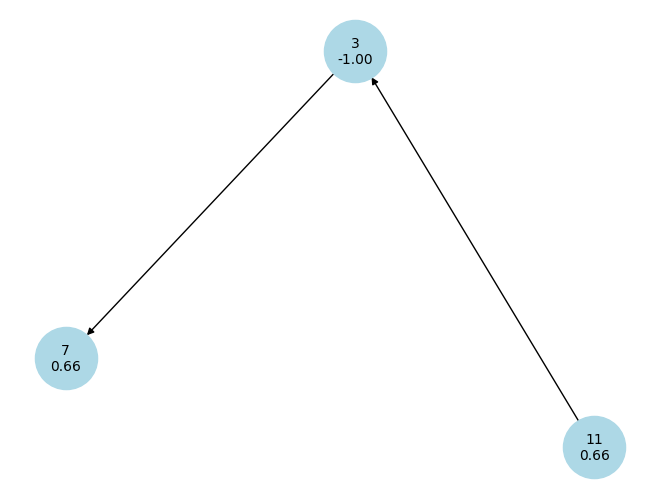

In [7]:
from networkx.drawing import spring_layout


def initialize_leaf_probabilities(node, X, y):
    if "prediction" in node:
        node["probability"] = np.mean(y)
        return
    false_child = node["false"]
    true_child = node["true"]
    false_indices = X.iloc[:, node["feature"]] == 0
    true_indices = X.iloc[:, node["feature"]] == 1
    initialize_leaf_probabilities(false_child, X[false_indices], y[false_indices])
    initialize_leaf_probabilities(true_child, X[true_indices], y[true_indices])


def convert_to_positive_leaf_graph(tree, X, y):
    initialize_leaf_probabilities(tree.source, X, y)
    tree_source = tree.source
    G = nx.DiGraph()
    node_queue = [tree_source]
    parents = [None]
    node_counter = 0
    while node_queue:
        node = node_queue.pop(0)
        if "prediction" in node:
            continue 
        false_child = node["false"]
        true_child = node["true"]
        false_leaf = "prediction" in false_child
        true_leaf = "prediction" in true_child
        if false_leaf and false_child["prediction"] == 1:
            G.add_node(node_counter, pred=false_child["probability"], feature=node["feature"])
        elif true_leaf and true_child["prediction"] == 1:
            G.add_node(node_counter, pred=true_child["probability"], feature=node["feature"])
        else:
            G.add_node(node_counter, pred=-1, feature=node["feature"])
        if parents[0] is not None:
            G.add_edge(parents[0], node_counter)
        parents.pop(0)
        node_counter += 1
        if not false_leaf:
            node_queue.insert(0, false_child)
            parents.insert(0, node_counter - 1)
        if not true_leaf:
            node_queue.insert(0, true_child)
            parents.insert(0, node_counter - 1)
    return G


def convert_to_full_leaf_graph(tree, X, y):
    initialize_leaf_probabilities(tree.source, X, y)
    tree_source = tree.source
    G = nx.DiGraph()
    node_queue = [tree_source]
    parents = [None]
    node_counter = 0
    while node_queue:
        node = node_queue.pop(0)
        if "prediction" in node:
            continue 
        false_child = node["false"]
        true_child = node["true"]
        false_leaf = "prediction" in false_child
        true_leaf = "prediction" in true_child
        current_node = node_counter
        if false_leaf and true_leaf:
            G.add_node(node_counter, pred=-1, feature=node["feature"])
            G.add_node(node_counter + 1, pred=false_child["probability"], feature=node["feature"])
            G.add_node(node_counter + 2, pred=true_child["probability"], feature=node["feature"])
            G.add_edge(node_counter, node_counter + 1)
            G.add_edge(node_counter, node_counter + 2)
            node_counter += 2
        elif false_leaf:
            G.add_node(node_counter, pred=false_child["probability"], feature=node["feature"])
        elif true_leaf:
            G.add_node(node_counter, pred=true_child["probability"], feature=node["feature"])
        else:
            G.add_node(node_counter, pred=-1, feature=node["feature"])
        if parents[0] is not None:
            G.add_edge(parents[0], current_node)
        parents.pop(0)
        node_counter += 1
        if not false_leaf:
            node_queue.insert(0, false_child)
            parents.insert(0, current_node)
        if not true_leaf:
            node_queue.insert(0, true_child)
            parents.insert(0, current_node)
    return G

def check_all_paths_descend(G):
    # make sure that every path from root to leaf descends in prediction probability
    for path in nx.all_simple_paths(G, source=0, target=[n for n in G.nodes if G.out_degree(n) == 0]):
        preds = [G.nodes[n]['pred'] for n in path if G.nodes[n]['pred'] >= 0]
        if not all(x >= y for x, y in zip(preds, preds[1:])):
            return False
    return True


G = convert_to_positive_leaf_graph(tree, X, y)
print("All paths descend:", check_all_paths_descend(G))
pos = spring_layout(G)

nx.draw(G, pos, with_labels=True, labels={n: f"{d['feature']}\n{d['pred']:0.2f}" for n, d in G.nodes(data=True)}, node_size=2000, node_color='lightblue', font_size=10)

All paths descend (full): False


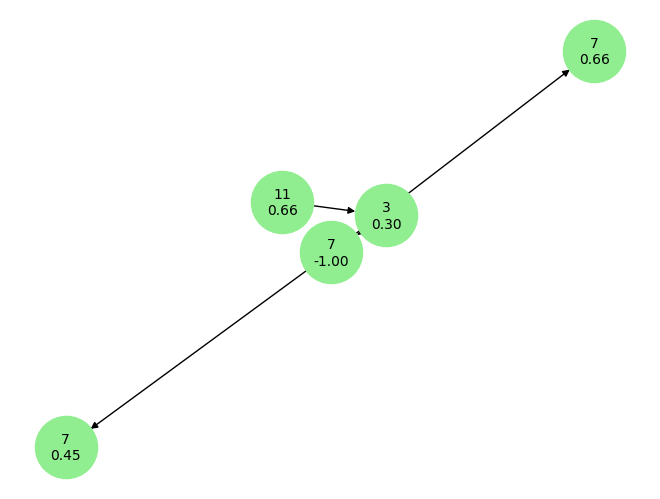

In [8]:
G_full = convert_to_full_leaf_graph(tree, X, y)
print("All paths descend (full):", check_all_paths_descend(G_full))
pos_full = spring_layout(G_full)

nx.draw(G_full, pos_full, with_labels=True, labels={n: f"{d['feature']}\n{d['pred']:0.2f}" for n, d in G_full.nodes(data=True)}, node_size=2000, node_color='lightgreen', font_size=10)

In [9]:
# find trees that satisfy the falling constraint
valid_trees = []
for i in tqdm(range(tf.get_tree_count())):
    tree = tf[i]
    G = convert_to_positive_leaf_graph(tree, X, y)
    if check_all_paths_descend(G):
        valid_trees.append(tree)
print(f"Found {len(valid_trees)} trees that satisfy the falling constraint out of {tf.get_tree_count()} total trees.")

100%|██████████| 8708/8708 [00:38<00:00, 225.01it/s]

Found 2875 trees that satisfy the falling constraint out of 8708 total trees.


In [10]:
fully_valid_trees = []
for i in tqdm(range(tf.get_tree_count())):
    tree = tf[i]
    G = convert_to_full_leaf_graph(tree, X, y)
    if check_all_paths_descend(G):
        fully_valid_trees.append(tree)
print(f"Found {len(fully_valid_trees)} trees that satisfy the full falling constraint (out of {tf.get_tree_count()} total trees).")

100%|██████████| 8708/8708 [00:38<00:00, 224.74it/s]

Found 641 trees that satisfy the full falling constraint (out of 8708 total trees).


All paths descend: True


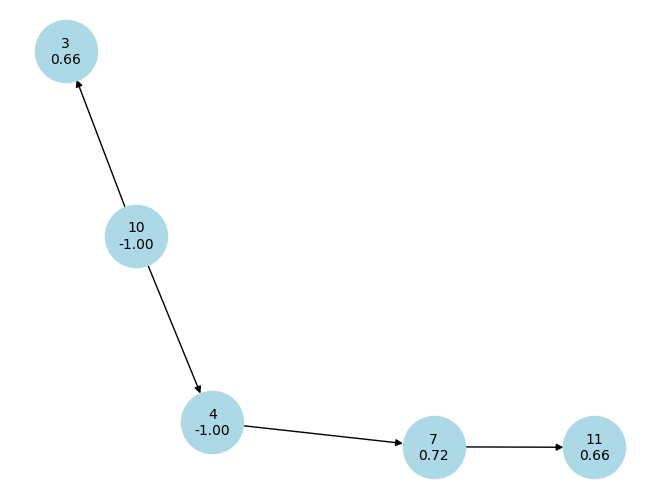

In [11]:
valid_tree = valid_trees[10]
G = convert_to_positive_leaf_graph(valid_tree, X, y)
print("All paths descend:", check_all_paths_descend(G))
pos = spring_layout(G)
nx.draw(G, pos, with_labels=True, labels={n: f"{d['feature']}\n{d['pred']:0.2f}" for n, d in G.nodes(data=True)}, node_size=2000, node_color='lightblue', font_size=10)

All paths descend (full): False


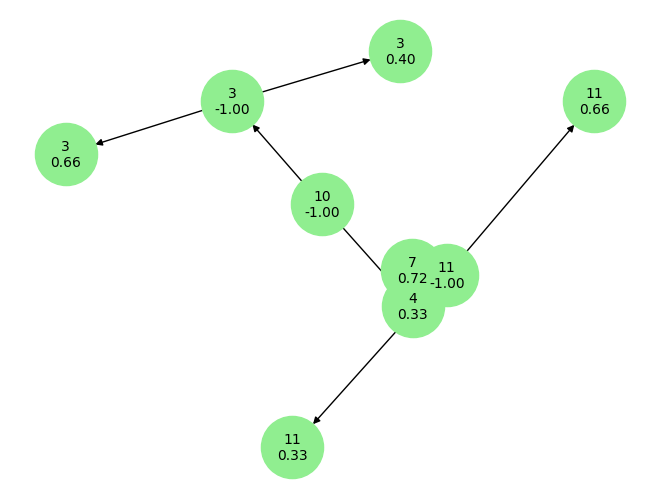

In [12]:
G_full = convert_to_full_leaf_graph(valid_tree, X, y)
print("All paths descend (full):", check_all_paths_descend(G_full))
pos_full = spring_layout(G_full)
nx.draw(G_full, pos_full, with_labels=True, labels={n: f"{d['feature']}\n{d['pred']:0.2f}" for n, d in G_full.nodes(data=True)}, node_size=2000, node_color='lightgreen', font_size=10)

In [13]:
tree_complexities = [tf[i].leaves() for i in range(tf.get_tree_count())]
valid_tree_complexities = [tree.leaves() for tree in valid_trees]
fully_valid_tree_complexities = [tree.leaves() for tree in fully_valid_trees]

print("Number of leaves in trees satisfying different constraints (avg, min, max)")
print("All trees:", f"{np.mean(tree_complexities):.2f}", np.min(tree_complexities), np.max(tree_complexities))
print("Positive leaf-valid trees:", f"{np.mean(valid_tree_complexities):.2f}", np.min(valid_tree_complexities), np.max(valid_tree_complexities))
print("Fully valid trees:", f"{np.mean(fully_valid_tree_complexities):.2f}", np.min(fully_valid_tree_complexities), np.max(fully_valid_tree_complexities))

Number of leaves in trees satisfying different constraints (avg, min, max)
All trees: 6.59 3 8
Positive leaf-valid trees: 6.41 3 7
Fully valid trees: 6.30 3 7
